In [1]:
import pandas as pd
from xgboost import XGBRegressor
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df=pd.read_csv("database_gas.csv")
# p = [1.19,	2.2,	19.5,	17.5,	25.0,	22.02,	17.5]
df.describe()

,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
count,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000
mean,20.115751,52.236446,102.459415,539.086523,500.289413,718.708761,672.788842,609.446752,120.124310
std,2.295836,4.343208,39.026812,34.934361,49.795030,31.296907,36.354293,42.703923,35.992508
min,13.530000,38.160000,21.000000,408.000000,262.000000,514.000000,447.000000,355.000000,74.000000
25%,18.640000,49.050000,76.000000,510.000000,468.000000,703.000000,655.000000,587.000000,103.000000
50%,20.100000,52.310000,105.000000,528.000000,502.000000,719.000000,674.000000,611.000000,113.000000
75%,21.630000,55.640000,117.000000,563.000000,536.000000,738.000000,693.000000,635.000000,128.000000
max,26.140000,69.260000,591.000000,632.000000,626.000000,808.000000,777.000000,727.000000,918.000000


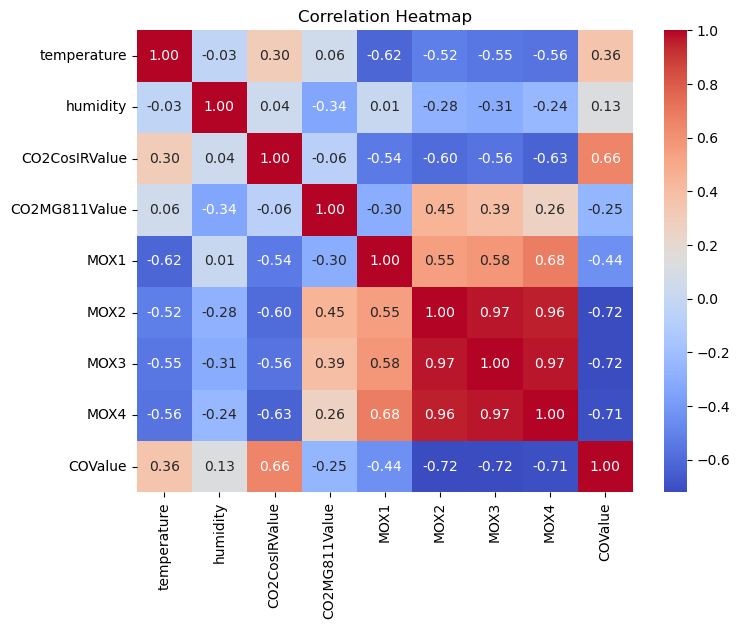

In [3]:
X = df.drop(['timestamp'], axis=1)
correlation_matrix = X.corr()
# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [4]:
del df['MOX2']
del df['MOX3']

In [5]:
# store the predicted values
predict_df = pd.DataFrame()
predict_df['timestamp'] = df.timestamp

In [6]:
def train_model(X, y, n_est = 100):
    my_model = XGBRegressor(n_estimators=n_est, learning_rate=0.5,max_depth=5,eval_metric='mae')
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=2,shuffle=True)
    my_model.fit(X_train, y_train)

    train_score = my_model.score(X_train,y_train)
    test_score = my_model.score(X_test,y_test)

    y_pred = my_model.predict(X_test)
    test_rmse = mean_squared_error(y_test, y_pred)

    my_model.fit(X,y)

    all_score = my_model.score(X,y)

    y_pred = my_model.predict(X)

    all_rmse = mean_squared_error(y, y_pred)
    
    return train_score, test_score, all_score, test_rmse, all_rmse, my_model


In [7]:

fields_humidity = ['temperature', 'CO2CosIRValue', 'CO2MG811Value', 'MOX1', 'MOX4', 'COValue']
X = df[fields_humidity].values
y = df['humidity'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_humidity = train_model(X, y, n_est=300)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9695208874897968 0.9654529947866844 0.9693651242822533 0.6518414621044434 0.5778781101299685


In [8]:
predict_df['humidity'] = model_humidity.predict(X)

In [9]:
fields_temperature = ['humidity', 'CO2CosIRValue', 'CO2MG811Value', 'MOX1', 'MOX4', 'COValue']
X = df[fields_temperature].values
y = df['temperature'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_temperature = train_model(X, y, n_est=200)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9665836247649342 0.9637138036661688 0.9662245720951133 0.19166133201998994 0.17802520356132104


In [10]:
predict_df['temperature'] = model_temperature.predict(X)

In [11]:
fields_CO2COS = ['temperature', 'humidity', 'CO2MG811Value', 'MOX1', 'MOX4', 'COValue']
X = df[fields_CO2COS].values
y = df['CO2CosIRValue'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_CO2COS = train_model(X, y, n_est=500)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9921643025778664 0.990669751981506 0.992231844548408 14.45514662744021 11.831587641904713


In [12]:
predict_df['CO2CosIRValue'] = model_CO2COS.predict(X)

In [13]:
fields_CO2MG8 = ['temperature', 'humidity', 'CO2CosIRValue', 'MOX1', 'MOX4', 'COValue']
X = df[fields_CO2MG8].values
y = df['CO2MG811Value'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_CO2MG8 = train_model(X, y, n_est=500)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.977539262712071 0.9728884101741845 0.9766492280992782 33.018059545323396 28.49743792368562


In [14]:
predict_df['CO2MG811Value'] = model_CO2MG8.predict(X)

In [15]:
fields_MOX1 = ['temperature', 'humidity',  'CO2CosIRValue', 'CO2MG811Value', 'MOX4', 'COValue']
X = df[fields_MOX1].values
y = df['MOX1'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_mox1 = train_model(X, y, n_est=500)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9847137492157046 0.981920355751981 0.984350981881003 45.02743243132029 38.80235132651824


In [16]:
predict_df['MOX1'] = model_mox1.predict(X)

In [17]:
fields_MOX4 = ['temperature', 'humidity',  'CO2CosIRValue', 'CO2MG811Value', 'MOX1', 'COValue']
X = df[fields_MOX4].values
y = df['MOX4'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_mox4 = train_model(X, y, n_est=500)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9874944514456618 0.9847068723419341 0.9875417603624541 28.1420334971744 22.719103123504077


In [18]:
predict_df['MOX4'] = model_mox4.predict(X)

In [19]:
fields_COValue = ['temperature', 'humidity',  'CO2CosIRValue', 'CO2MG811Value', 'MOX1', 'MOX4']
X = df[fields_COValue].values
y = df['COValue'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_COValue = train_model(X, y, n_est=500)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9902913557385585 0.9869194741232455 0.9899888194975082 17.291446326909714 12.969059062950322


In [20]:
predict_df['COValue'] = model_COValue.predict(X)

In [21]:
predict_df.to_csv("predicted_values.csv")

In [22]:
# use the above model to estimate the sensors values using gausian model

In [23]:
particles =np.array(
    [
        min(df.temperature) +  (max(df.temperature) - min(df.temperature)) * np.random.random(1000),
        min(df.humidity) +  (max(df.humidity) - min(df.humidity)) * np.random.random(1000),
        min(df.CO2CosIRValue) +  (max(df.CO2CosIRValue) - min(df.CO2CosIRValue)) * np.random.random(1000),
        min(df.CO2MG811Value) +  (max(df.CO2MG811Value) - min(df.CO2MG811Value)) * np.random.random(1000),
        min(df.MOX1) +  (max(df.MOX1) - min(df.MOX1)) * np.random.random(1000),
        min(df.MOX4) +  (max(df.MOX4) - min(df.MOX4)) * np.random.random(1000),
        min(df.COValue) +  (max(df.COValue) - min(df.COValue)) * np.random.random(1000)
        
    ]

).T
dfp = pd.DataFrame(data=particles, columns=list(df.columns)[1:])


In [24]:
dfp

,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX4,COValue
0,15.564006,43.926288,474.628180,511.339296,273.689842,498.914417,112.286256
1,18.067530,51.564019,428.300638,486.314613,335.091557,429.743219,699.904346
2,15.808016,42.373676,199.378610,598.716659,365.550578,448.898039,725.669798
3,25.656986,58.477376,293.332132,502.983567,442.575362,377.251117,230.817334
4,24.703388,56.695684,424.001542,457.484577,609.222524,575.722663,334.474131
...,...,...,...,...,...,...,...
995,17.192643,43.515688,539.022935,570.806799,609.225505,519.731281,892.428034
996,20.461557,44.690808,428.593824,484.489531,328.649547,661.533434,566.536396
997,24.281142,54.993496,224.815494,625.225522,591.741757,604.061215,813.897102
998,18.939120,54.357871,230.889994,503.226700,309.695144,477.653686,334.265791


In [25]:
dfp.describe()

,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX4,COValue
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,19.880530,53.601344,301.688589,518.210638,447.219188,545.632332,491.608688
std,3.642306,8.923238,163.773615,64.608965,106.576724,106.749259,245.042296
min,13.533676,38.207598,21.711654,408.034495,262.214607,355.416639,74.474490
25%,16.751721,46.006672,168.192563,463.676584,355.792672,455.816072,282.893884
50%,19.874121,53.365272,297.496489,514.815457,442.553029,544.231186,483.214101
75%,23.028372,61.218358,439.723778,573.303030,544.426613,642.286551,707.267147
max,26.127137,69.174284,590.981077,631.918583,625.893495,726.959246,917.793790


In [26]:
df.describe()

,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX4,COValue
count,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000
mean,20.115751,52.236446,102.459415,539.086523,500.289413,609.446752,120.124310
std,2.295836,4.343208,39.026812,34.934361,49.795030,42.703923,35.992508
min,13.530000,38.160000,21.000000,408.000000,262.000000,355.000000,74.000000
25%,18.640000,49.050000,76.000000,510.000000,468.000000,587.000000,103.000000
50%,20.100000,52.310000,105.000000,528.000000,502.000000,611.000000,113.000000
75%,21.630000,55.640000,117.000000,563.000000,536.000000,635.000000,128.000000
max,26.140000,69.260000,591.000000,632.000000,626.000000,727.000000,918.000000


In [27]:
models = [model_temperature, model_humidity, model_CO2COS, model_CO2MG8, model_mox1, model_mox4, model_COValue]
fields = [fields_temperature, fields_humidity, fields_CO2COS, fields_CO2MG8, fields_MOX1, fields_MOX4, fields_COValue]
p = [1.19,	2.2,	19.5,	17.5,	25.0,	22.02,	17.5]

In [28]:
row = list(df.iloc[0])[1:]
row

[19.48, 54.86, 128.0, 563.0, 476.0, 565.0, 128.0]

In [29]:
row = list(df.iloc[0])[1:]
new_value = [list(df.iloc[0])[0]]
weights = np.ones(1000)/ 100
for i in range(len(models)):
    y = models[i].predict(dfp[fields[i]].values)
    weights = weights*np.exp(-0.5 * ((row[i] - y)/p[i])**2)
weights = weights/np.sum(weights)
value = np.average(dfp, weights=weights, axis=0)
new_value.extend(value)
new_value

['2019-11-06 11:37:13.038174+01:00',
 17.745944473769192,
 53.4814356481055,
 59.62294570691536,
 558.1272739088542,
 502.91794859351074,
 554.6468695962149,
 554.1320307629591]

In [30]:
estimate_df = pd.DataFrame(columns=df.columns)
for k in range(len(df)):
    row = list(df.iloc[k])[1:]
    new_value = [list(df.iloc[k])[0]]
    weights = np.ones(1000)/ 1000
    for i in range(len(models)):
        y = models[i].predict(dfp[fields[i]].values)
        weights = weights*np.exp(-0.5 * ((row[i] - y)/p[i])**2)
    weights = weights/np.sum(weights)
    value = np.average(dfp, weights=weights, axis=0)
    new_value.extend(value)
    estimate_df.loc[len(estimate_df)] = new_value

In [31]:
estimate_df.to_csv("estimated_values.csv")

In [32]:
estimate_df.describe()

,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX4,COValue
count,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000,416153.000000
mean,18.814879,50.953625,149.080221,557.246341,490.363682,583.805456,273.866280
std,3.480260,5.790317,108.209067,36.446203,86.413764,57.484368,165.822520
min,13.758220,38.452027,24.006001,409.689836,262.443925,368.264816,76.655782
25%,16.122024,48.358665,78.536785,524.105264,442.870412,554.136298,140.723953
50%,16.829177,51.097626,100.480635,556.925772,513.978620,596.660729,231.360115
75%,21.488498,53.346392,211.474934,587.782580,549.975060,616.552582,335.076984
max,26.048037,68.956618,589.802054,631.672307,622.716376,713.510228,917.748989
